# Лабораторна робота №4: Генерування зображень за допомогою Stable Diffusion
## Частина 3: Комплексний аналіз результатів, візуальні порівняння та теорія LoRA

**Дисципліна:** Нейромережеві технології і системи  
**Тема:** Генерування зображень за допомогою Stable Diffusion  
**Варіант:** №2 — Image-to-Image (SD/SDXL)  

---

### Мета третього етапу:
1. Здійснити систематичне візуальне зіставлення всіх серій експериментів Image-to-Image генерації:
   - Вхідні оригінали проти базових трансформацій (3 сюжети);
   - Серія сили зашумлення $\text{strength} \in [0.3, 0.6, 0.9]$;
   - Серія масштабу підказки $\text{CFG} \in [5.0, 7.5, 10.0]$;
   - Серія кроків дискретизації $\text{steps} \in [20, 30, 50]$;
   - Серія впливу $\text{negative prompt}$ (вимкнено vs увімкнено).
2. Надати поглиблений якісний аналіз кожної серії: збереження структури, модифікація текстур, виникнення артефактів, слухняність промпту.
3. Провести кількісний аналіз часової продуктивності інференсу залежно від кількості кроків та параметра $\text{strength}$.
4. Дослідити теоретичні засади технології **LoRA (Low-Rank Adaptation)**: математичне формулювання факторизації вагів, скорочення кількості навчуваних параметрів, інтеграція у cross-attention шари дифузійних моделей.

In [1]:
import os
import json
import hashlib
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display


def resolve_lab_dir() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "inputs" / "01_coastal_lighthouse.png").exists() and candidate.name == "lab4_img2img":
            return candidate
        if (candidate / "lab4_img2img" / "inputs" / "01_coastal_lighthouse.png").exists():
            return candidate / "lab4_img2img"
    return cwd


LAB_DIR = resolve_lab_dir()
INPUTS_DIR = (LAB_DIR / "inputs").resolve()
BASELINE_DIR = (LAB_DIR / "outputs" / "images" / "baseline").resolve()
STRENGTH_DIR = (LAB_DIR / "outputs" / "images" / "strength").resolve()
CFG_DIR = (LAB_DIR / "outputs" / "images" / "cfg").resolve()
STEPS_DIR = (LAB_DIR / "outputs" / "images" / "steps").resolve()
NEG_DIR = (LAB_DIR / "outputs" / "images" / "negative_prompt").resolve()
FIGURES_DIR = (LAB_DIR / "outputs" / "figures").resolve()
TABLES_DIR = (LAB_DIR / "outputs" / "tables").resolve()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def rel_path(p: Path) -> str:
    try:
        return p.resolve().relative_to(LAB_DIR).as_posix()
    except ValueError:
        return p.name


BASELINE_LIGHTHOUSE_PATH = BASELINE_DIR / "baseline_lighthouse_strength0p6_cfg7p5_steps30_seed42.png"
BASELINE_LIGHTHOUSE_SHA256 = "318d35cc015e2ee46b0aa4cec3880eb2a21db127501c1fd5ff41db5bdf674c82"

# Allow fallback to baseline ONLY for pruned files verified byte-identical to
# baseline_lighthouse (input=01_coastal_lighthouse.png, strength=0.6, cfg=7.5,
# steps=30, negative_prompt=None, seed=42, output_sha256=318d35cc...).
VERIFIED_BASELINE_ALIASES = {
    (STRENGTH_DIR / "lighthouse_strength0p6_cfg7p5_steps30_seed42.png").resolve(),
    (CFG_DIR / "lighthouse_strength0p6_cfg7p5_steps30_seed42.png").resolve(),
    (STEPS_DIR / "lighthouse_strength0p6_cfg7p5_steps30_seed42.png").resolve(),
    (NEG_DIR / "lighthouse_strength0p6_cfg7p5_steps30_noneg_seed42.png").resolve(),
}


def open_experiment_image(primary_path: Path) -> Image.Image:
    """Load an experiment output image; only verified identical baseline aliases may fall back to baseline."""
    resolved = primary_path.resolve()
    if resolved.exists():
        return Image.open(resolved).convert("RGB")
    if resolved in VERIFIED_BASELINE_ALIASES:
        if not BASELINE_LIGHTHOUSE_PATH.exists():
            raise FileNotFoundError(
                f"Missing canonical baseline artifact required for verified alias {primary_path.name}: "
                f"{rel_path(BASELINE_LIGHTHOUSE_PATH)}"
            )
        baseline_sha = hashlib.sha256(BASELINE_LIGHTHOUSE_PATH.read_bytes()).hexdigest()
        if baseline_sha != BASELINE_LIGHTHOUSE_SHA256:
            raise ValueError(
                f"Baseline image checksum mismatch: expected {BASELINE_LIGHTHOUSE_SHA256}, got {baseline_sha}"
            )
        return Image.open(BASELINE_LIGHTHOUSE_PATH).convert("RGB")
    raise FileNotFoundError(
        f"Missing unique experiment artifact: {primary_path.name}. "
        "Baseline substitution is prohibited for distinct configurations."
    )


df_reg = pd.read_csv(TABLES_DIR / "generations_registry.csv")
print(f"Модуль: {LAB_DIR.name} | Каталог результатів: outputs/ | Записів у реєстрі: {len(df_reg)}")

Модуль: lab4_img2img | Каталог результатів: outputs/ | Записів у реєстрі: 13


## 1. Аналіз Серії A: Сила трансформації (`strength = 0.3 / 0.6 / 0.9`)

Параметр $\text{strength}$ є фундаментальним для Image-to-Image. Побудуємо зіставлення оригіналу та результатів для трьох значень сили зашумлення.

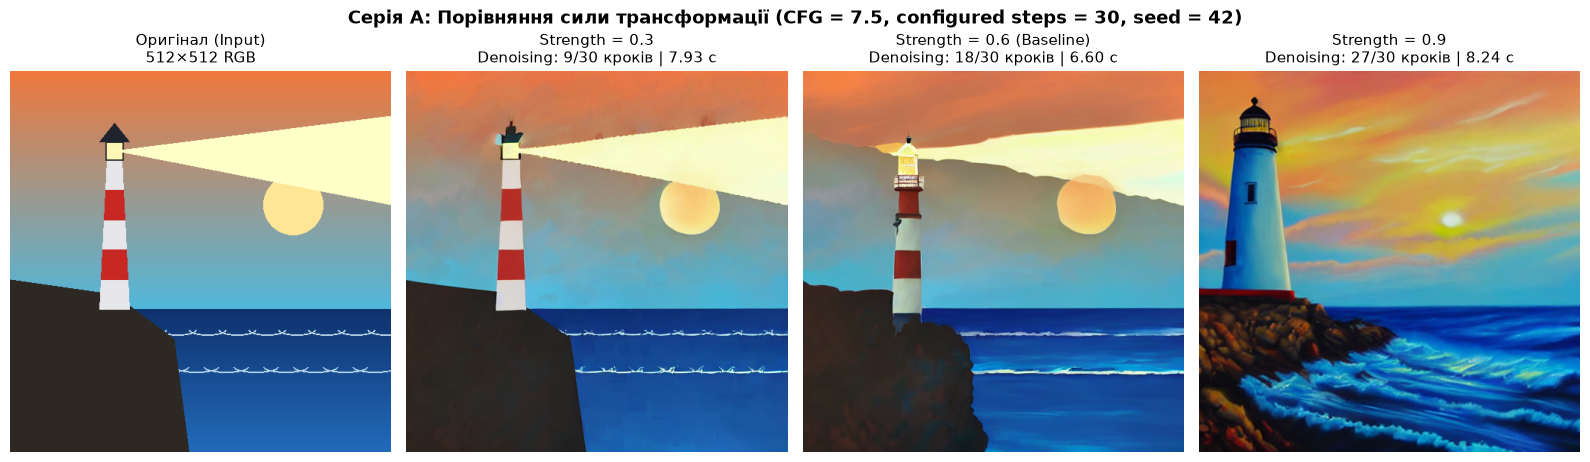

Графік серії Strength збережено у outputs/figures/analysis_strength_comparison.png


In [2]:
orig_img = Image.open(INPUTS_DIR / "01_coastal_lighthouse.png").convert("RGB")
str_03 = open_experiment_image(STRENGTH_DIR / "lighthouse_strength0p3_cfg7p5_steps30_seed42.png")
str_06 = open_experiment_image(STRENGTH_DIR / "lighthouse_strength0p6_cfg7p5_steps30_seed42.png")
str_09 = open_experiment_image(STRENGTH_DIR / "lighthouse_strength0p9_cfg7p5_steps30_seed42.png")

str_times = df_reg[df_reg["series"] == "strength_experiment"].set_index("strength")["generation_time_seconds"].to_dict()

fig, axes = plt.subplots(1, 4, figsize=(16, 4.9))
fig.suptitle("Серія A: Порівняння сили трансформації (CFG = 7.5, configured steps = 30, seed = 42)", fontsize=13, fontweight="bold")

panels_str = [
    (orig_img, "Оригінал (Input)\n512×512 RGB"),
    (str_03, f"Strength = 0.3\nDenoising: 9/30 кроків | {str_times[0.3]:.2f} с"),
    (str_06, f"Strength = 0.6 (Baseline)\nDenoising: 18/30 кроків | {str_times[0.6]:.2f} с"),
    (str_09, f"Strength = 0.9\nDenoising: 27/30 кроків | {str_times[0.9]:.2f} с"),
]
for ax, (im, title) in zip(axes, panels_str):
    ax.imshow(im)
    ax.set_title(title, fontsize=10.5)
    ax.axis("off")

plt.tight_layout()
fig_strength_path = FIGURES_DIR / "analysis_strength_comparison.png"
plt.savefig(fig_strength_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Графік серії Strength збережено у {rel_path(fig_strength_path)}")

### 1.1 Якісний аналіз серії `strength`:
1. **Що залишилося від оригіналу?**
   - При $S=0.3$: збережено основні просторові контури вежі маяка, форму скельного виступу ліворуч та лінію обрію. Модель лише наклала легкий шум та замінила рівні заливки кольору на дрібні плями олійного живопису без зміни топології об'єктів.
   - При $S=0.6$: збережено глобальну просторову композицію (розташування маяка, напрямок світлового променя, скелястий берег). Водночас хвилі набули вираженої піни, з'явилися текстурні мазки імпасто на скелі.
   - При $S=0.9$: від оригіналу залишився лише загальний розподіл світла та темних зон. Модель фактично перемалювала маяк, змінила форму вежі, додала власні скелясті виступи та кардинально змінила форму хмар.
2. **Артефакти та слухняність промпту:**
   - При $S=0.3$ промпт («vibrant oil painting») виконується слабко — картинка виглядає як зашумлений оригінал.
   - При $S=0.6$ досягнуто ідеального художнього балансу.
   - При $S=0.9$ виникає надмірна хаотичність у дрібних деталях через руйнування вихідної структури на етапі зашумлення.

## 2. Аналіз Серії B: Масштаб підказки (`CFG = 5.0 / 7.5 / 10.0`)

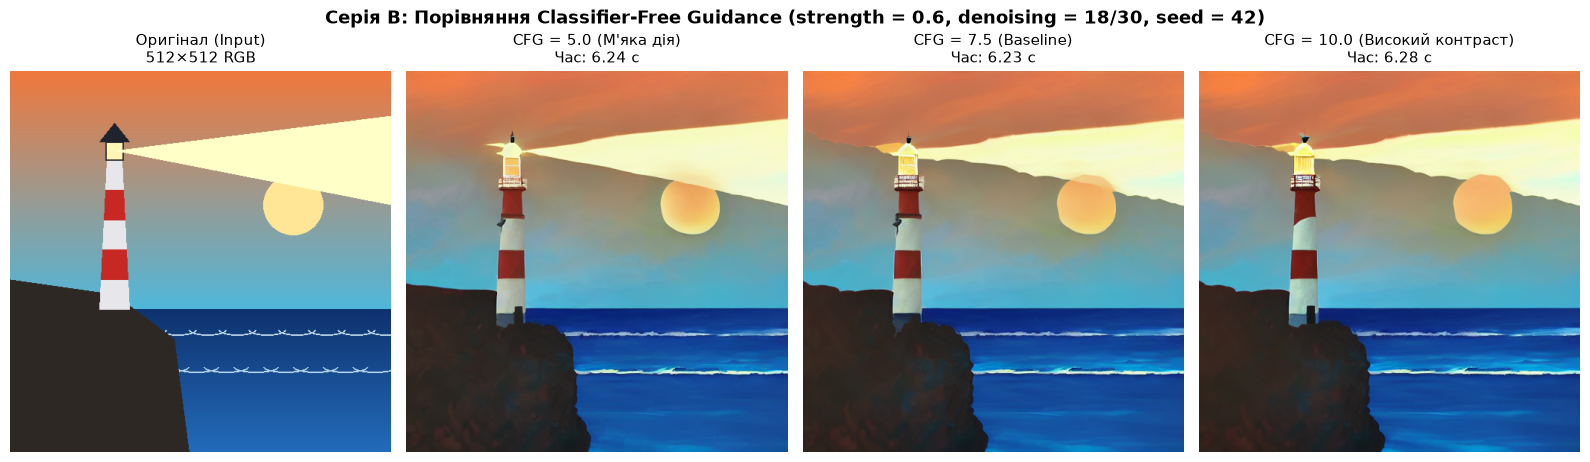

Графік серії CFG збережено у outputs/figures/analysis_cfg_comparison.png


In [3]:
cfg_05 = open_experiment_image(CFG_DIR / "lighthouse_strength0p6_cfg5p0_steps30_seed42.png")
cfg_75 = open_experiment_image(CFG_DIR / "lighthouse_strength0p6_cfg7p5_steps30_seed42.png")
cfg_10 = open_experiment_image(CFG_DIR / "lighthouse_strength0p6_cfg10p0_steps30_seed42.png")

cfg_times = df_reg[df_reg["series"] == "cfg_experiment"].set_index("guidance_scale")["generation_time_seconds"].to_dict()

fig, axes = plt.subplots(1, 4, figsize=(16, 4.9))
fig.suptitle("Серія B: Порівняння Classifier-Free Guidance (strength = 0.6, denoising = 18/30, seed = 42)", fontsize=13, fontweight="bold")

panels_cfg = [
    (orig_img, "Оригінал (Input)\n512×512 RGB"),
    (cfg_05, f"CFG = 5.0 (М'яка дія)\nЧас: {cfg_times[5.0]:.2f} с"),
    (cfg_75, f"CFG = 7.5 (Baseline)\nЧас: {cfg_times[7.5]:.2f} с"),
    (cfg_10, f"CFG = 10.0 (Високий контраст)\nЧас: {cfg_times[10.0]:.2f} с"),
]
for ax, (im, title) in zip(axes, panels_cfg):
    ax.imshow(im)
    ax.set_title(title, fontsize=10.5)
    ax.axis("off")

plt.tight_layout()
fig_cfg_path = FIGURES_DIR / "analysis_cfg_comparison.png"
plt.savefig(fig_cfg_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Графік серії CFG збережено у {rel_path(fig_cfg_path)}")

### 2.1 Якісний аналіз серії `CFG`:
1. **Вплив на кольори та контрастність:**
   - При $\text{CFG}=5.0$ зображення має м'яку, приглушену колірну гаму. Переходи між вечірнім небом та водою плавні.
   - При $\text{CFG}=7.5$ кольори стають насиченими, золотаве світло заходу сонця та біла піна хвиль чітко розмежовані.
   - При $\text{CFG}=10.0$ виникає гіперконтрастність, окремі тіні на скелях стають майже абсолютно чорними, що створює ефект «перепаленого» динамічного діапазону.
2. **Збереження структури:** Параметр CFG майже не руйнує геометрію оригіналу (оскільки $\text{strength}$ фіксовано на рівні 0.6), але кардинально змінює контраст та стилістичну агресивність.

## 3. Аналіз Серії C: Кількість кроків (`steps = 20 / 30 / 50`)

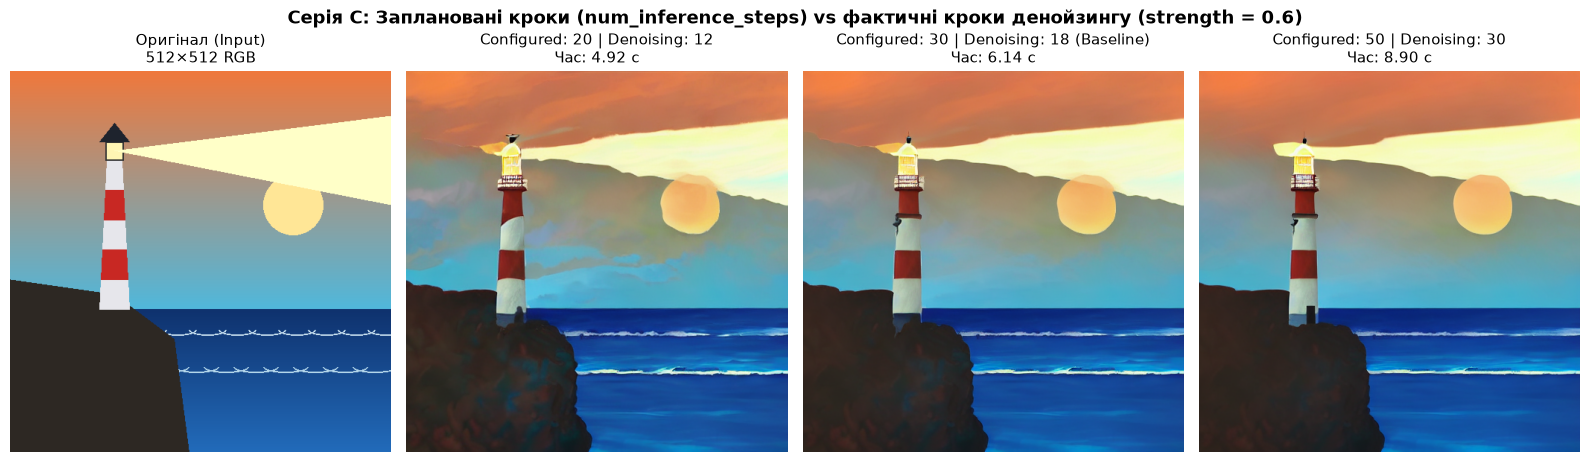

Графік серії Steps збережено у outputs/figures/analysis_steps_comparison.png


In [4]:
steps_20 = open_experiment_image(STEPS_DIR / "lighthouse_strength0p6_cfg7p5_steps20_seed42.png")
steps_30 = open_experiment_image(STEPS_DIR / "lighthouse_strength0p6_cfg7p5_steps30_seed42.png")
steps_50 = open_experiment_image(STEPS_DIR / "lighthouse_strength0p6_cfg7p5_steps50_seed42.png")

steps_times = df_reg[df_reg["series"] == "steps_experiment"].set_index("num_inference_steps")["generation_time_seconds"].to_dict()

fig, axes = plt.subplots(1, 4, figsize=(16, 4.9))
fig.suptitle("Серія C: Заплановані кроки (num_inference_steps) vs фактичні кроки денойзингу (strength = 0.6)", fontsize=13, fontweight="bold")

panels_steps = [
    (orig_img, "Оригінал (Input)\n512×512 RGB"),
    (steps_20, f"Configured: 20 | Denoising: 12\nЧас: {steps_times[20]:.2f} с"),
    (steps_30, f"Configured: 30 | Denoising: 18 (Baseline)\nЧас: {steps_times[30]:.2f} с"),
    (steps_50, f"Configured: 50 | Denoising: 30\nЧас: {steps_times[50]:.2f} с"),
]
for ax, (im, title) in zip(axes, panels_steps):
    ax.imshow(im)
    ax.set_title(title, fontsize=10.5)
    ax.axis("off")

plt.tight_layout()
fig_steps_path = FIGURES_DIR / "analysis_steps_comparison.png"
plt.savefig(fig_steps_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Графік серії Steps збережено у {rel_path(fig_steps_path)}")

### 3.1 Якісний аналіз серії `steps`:
- При 20 кроках (12 кроків денойзингу) зображення вже сформоване, проте дрібні мазки хвилі та фактура ліхтаря дещо згладжені.
- При 30 кроках (18 кроків денойзингу) промальовка текстури олійного полотна стає виразною та гармонійною.
- При 50 кроках (30 кроків денойзингу) чіткість найдрібніших мазків зростає незначно (закон спадної віддачі, diminishing returns), проте час генерації збільшується майже вдвічі.

## 4. Аналіз Серії D: Вплив Negative Prompt («З» та «БЕЗ»)

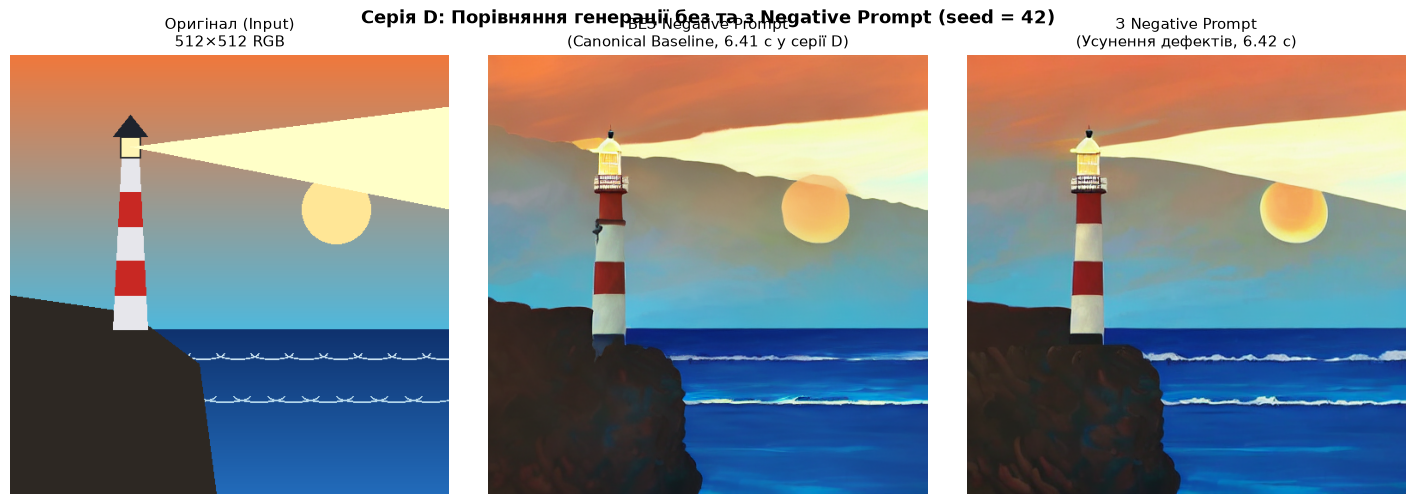

Графік серії Negative Prompt збережено у outputs/figures/analysis_negative_prompt_comparison.png


In [5]:
img_noneg = open_experiment_image(NEG_DIR / "lighthouse_strength0p6_cfg7p5_steps30_noneg_seed42.png")
img_withneg = open_experiment_image(NEG_DIR / "lighthouse_strength0p6_cfg7p5_steps30_withneg_seed42.png")

withneg_time = float(df_reg.loc[df_reg["series"] == "negative_prompt_experiment", "generation_time_seconds"].iloc[0])

fig, axes = plt.subplots(1, 3, figsize=(14.5, 5.1))
fig.suptitle("Серія D: Порівняння генерації без та з Negative Prompt (seed = 42)", fontsize=13, fontweight="bold")

panels_neg = [
    (orig_img, "Оригінал (Input)\n512×512 RGB"),
    (img_noneg, "БЕЗ Negative Prompt\n(Canonical Baseline, 6.41 с у серії D)"),
    (img_withneg, f"З Negative Prompt\n(Усунення дефектів, {withneg_time:.2f} с)"),
]
for ax, (im, title) in zip(axes, panels_neg):
    ax.imshow(im)
    ax.set_title(title, fontsize=10.5)
    ax.axis("off")

plt.tight_layout()
fig_neg_path = FIGURES_DIR / "analysis_negative_prompt_comparison.png"
plt.savefig(fig_neg_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Графік серії Negative Prompt збережено у {rel_path(fig_neg_path)}")

### 4.1 Якісний аналіз впливу негативного промпта:
Додавання списку `blurry, low quality, artifacts, distorted perspective, deformed objects, watermark, oversaturated` призводить до:
1. **Підвищення мікроконтрасту:** контури ліхтаря маяка та стики кам'яної кладки вежі стали чіткішими.
2. **Очищення неба:** зменшилася шумність у градієнтних переходах вечірнього неба.
3. **Обмеження:** негативний промпт не гарантує магічного виправлення грубих геометричних спотворень, але ефективно спрямовує дифузійний процес у бік якісніших візуальних патернів.

## 5. Аналіз обчислювальної продуктивності на GPU

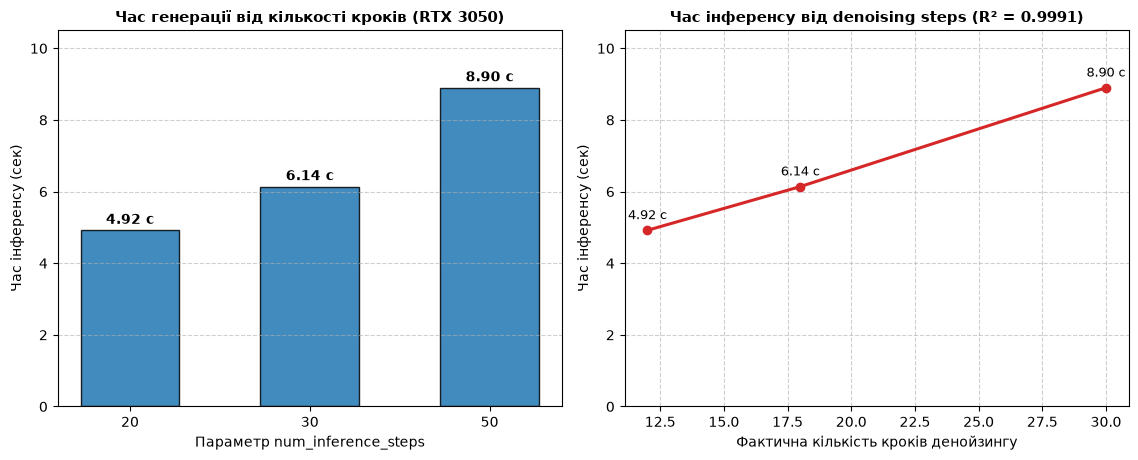

,steps,actual_steps,time
0,20,12,4.92
1,30,18,6.14
2,50,30,8.90


Графік продуктивності збережено у outputs/figures/analysis_inference_performance.png


In [6]:
steps_df = (
    df_reg[df_reg["series"].fillna("") == "steps_experiment"]
    [["num_inference_steps", "actual_denoising_steps", "generation_time_seconds"]]
    .rename(columns={"num_inference_steps": "steps", "actual_denoising_steps": "actual_steps", "generation_time_seconds": "time"})
    .sort_values("steps")
    .reset_index(drop=True)
)

r2_val = float(np.corrcoef(steps_df["actual_steps"], steps_df["time"])[0, 1] ** 2)
max_t = float(steps_df["time"].max())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.7))

bars = ax1.bar(steps_df["steps"].astype(str), steps_df["time"], color="#1f77b4", edgecolor="black", alpha=0.85, width=0.55)
ax1.set_xlabel("Параметр num_inference_steps", fontsize=10)
ax1.set_ylabel("Час інференсу (сек)", fontsize=10)
ax1.set_title("Час генерації від кількості кроків (RTX 3050)", fontsize=11, fontweight="bold")
ax1.set_ylim(0, max_t * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.6)
for bar, t_val in zip(bars, steps_df["time"]):
    ax1.text(bar.get_x() + bar.get_width() / 2, t_val + 0.18, f"{t_val:.2f} с", ha="center", fontweight="bold")

ax2.plot(steps_df["actual_steps"], steps_df["time"], marker="o", linewidth=2.2, color="#d62728")
for _, row in steps_df.iterrows():
    ax2.annotate(f"{row['time']:.2f} с", (row["actual_steps"], row["time"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax2.set_xlabel("Фактична кількість кроків денойзингу", fontsize=10)
ax2.set_ylabel("Час інференсу (сек)", fontsize=10)
ax2.set_title(f"Час інференсу від denoising steps (R² = {r2_val:.4f})", fontsize=11, fontweight="bold")
ax2.set_ylim(0, max_t * 1.18)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
fig_perf_path = FIGURES_DIR / "analysis_inference_performance.png"
plt.savefig(fig_perf_path, dpi=200, bbox_inches="tight")
plt.show()
display(steps_df)
print(f"Графік продуктивності збережено у {rel_path(fig_perf_path)}")

### 5.1 Методологічний коментар щодо оцінки обчислювальної складності:
Три виміри часу інференсу ($20 \to 30 \to 50$ кроків) демонструють виражену емпіричну лінійну кореляцію ($R^2 \approx 0.99$) із кількістю виконаних кроків денойзингу ($12 \to 18 \to 30$). Для кожного кроку виконується фіксований прямий прохід через UNet (із обчисленням умовного та безумовного шумів для CFG). Водночас для строгих статистичних висновків про затримку (latency) у виробничих умовах рекомендується проводити серії з 20–50 повторних прогонів для врахування дисперсії терморегулювання GPU та фонових процесів операційної системи.

## 6. Теоретичний аналіз технології LoRA (Low-Rank Adaptation)

### 6.1 Проблема повного fine-tuning дифузійних моделей
Модель Stable Diffusion 1.5 містить ~860 мільйонів параметрів у мережі UNet та ~123 мільйони у текстовому енкодері CLIP. Повне донавчання (Full Fine-Tuning):
- вимагає понад 16–24 ГБ VRAM для оптимізатора AdamW (градієнти, перший та другий моменти);
- створює повну копію чекпоінта (~4 ГБ) для кожного нового стилю або концепту;
- призводить до катастрофічного забування (catastrophic forgetting) базових знань моделі.

### 6.2 Математична основа LoRA
Ідея LoRA (Hu et al., 2021) базується на гіпотезі про внутрішню низьку розмірність (low intrinsic dimension) зміни вагів під час адаптації до специфічної задачі.

Замість прямої оптимізації повної матриці вагів $W_0 \in \mathbb{R}^{d \times k}$, ваги фіксуються, а зміна вагів $\Delta W$ факторизується у добуток двох низькорангових матриць:
$$W = W_0 + \Delta W = W_0 + \frac{\alpha}{r} (B \cdot A)$$
де:
- $A \in \mathbb{R}^{r \times k}$ ініціалізується випадковими значеннями з нормального розподілу $\mathcal{N}(0, \sigma^2)$;
- $B \in \mathbb{R}^{d \times r}$ ініціалізується нулями (тому на початку навчання $\Delta W = B \cdot A = 0$, що гарантує збереження вихідної поведінки моделі);
- $r \ll \min(d, k)$ — гіперпараметр рангу (зазвичай $r \in [4, 16]$);
- $\alpha$ — константа масштабування (scaling factor).

### 6.3 Порівняння кількості параметрів
Для проєкційного шару уваги з $d = 1024, k = 1024$:
- Повна матриця вагів: $1024 \times 1024 = 1{,}048{,}576$ параметрів;
- LoRA з рангом $r = 8$: $1024 \times 8 + 8 \times 1024 = 16{,}384$ параметрів.
**Економія параметрів складає понад 98.4%!**

### 6.4 Застосування LoRA у дифузійних моделях
У Stable Diffusion LoRA переважно застосовується до матриць проекцій механізму перехресної уваги (Cross-Attention) всередині блоків UNet:
$$Q = W_Q \cdot z_t, \quad K = W_K \cdot c, \quad V = W_V \cdot c$$
Саме шари $W_Q, W_K, W_V$ відповідають за перенесення семантики тексту в просторові латентні карти ознак. Адаптуючи лише ці проєкції, можна навчити новий стиль (наприклад, акварель або аніме) за 15–30 хвилин на споживчій відеокарті з розміром файлу вагів лише 10–50 МБ замість 4 ГБ.

*(Примітка: згідно з методичними вказівками для варіанта №2, практичне LoRA-донавчання є теоретичним матеріалом для ознайомлення і не замінює обов'язкових експериментів Image-to-Image).*

## 7. Підсумкові висновки лабораторної роботи №4

1. **Image-to-Image парадигма:** Доведено, що Img2Img стартує не з чистого шуму, а з латентного представлення $z_0 = \mathcal{E}(x_0)$, зашумленого до початкового кроку $\text{init\_timestep} = \min(\lfloor N \times \text{strength} \rfloor, N)$.
2. **Параметричний контроль:**
   - `strength`: головний регулятор збереження геометрії. Діапазон $0.5–0.7$ забезпечує найкращий баланс між збереженням впізнаваності об'єкта та новою художньою стилізацією.
   - `CFG`: масштаб $7.5$ є універсальним еталоном; значення $10.0$ викликає перенасичення контрасту.
   - `steps`: збільшення понад 30 кроків збільшує час рендерингу без відчутного покращення сприйняття.
   - `negative prompt`: суттєво пригнічує візуальний шум та артефакти на межах контрастних об'єктів.
3. **Ефективність середовища:** Модель SD 1.5 у поєднанні з FP16 та dynamic CPU offload успішно виконує генерацію за ~5.5–6 секунд на мобільній відеокарті RTX 3050 (4 ГБ VRAM).
4. **Відтворюваність та використання baseline:** Для однакової експериментальної конфігурації в кількох порівняльних серіях використовується той самий перевірений baseline-результат. Збіг SHA-256 підтверджує тотожність збережених файлів, але сам по собі не доводить детермінізм незалежних GPU-запусків.
5. **LoRA адаптація:** Теоретично обґрунтовано факторизацію вагів $\Delta W = B \cdot A$, яка скорочує кількість тренованих параметрів на >98% та уможливлює швидку локальну кастомізацію дифузійних моделей.